# Online dependence estimation — experiment analysis

Loads the `experiment_<scenario>.csv` files produced by the C++ harness and plots each
estimator's tracking of the true Spearman's rho, plus an RMSE summary.

**Prerequisites** (run in a terminal from the repo root first):
```bash
pip install pandas matplotlib numpy jupyter
make experiment
for s in constant drift jump stochastic oscillate; do ./experiment $s; done
```
Then run this notebook top to bottom.

In [8]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Experiments write their CSVs to the repo root (where you run ./experiment).
# Find that root by walking up from the kernel's cwd until we hit the folder
# holding the Makefile + src/, so it works no matter where Jupyter launched.
def _find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for d in [p, *p.parents]:
        if (d / 'Makefile').exists() and (d / 'src').is_dir():
            return d
    return p  # fallback: kernel cwd

DATA_DIR = str(_find_repo_root())
SCENARIOS = ['constant', 'drift', 'jump', 'stochastic', 'oscillate']
BURN_IN = 500  # steps to skip before scoring, matches the C++ harness

# Consistent colours across scenarios (match the C++/React client).
COLORS = {
    'xiao': '#ffb800',
    'xiao_ew': '#ff5555',
    'hermite': '#22d3ee',
    'hermite_ew': '#a78bfa',
    'windowed_rank': '#888888',
}
print('looking for CSVs in:', DATA_DIR)
found = [s for s in SCENARIOS if os.path.exists(os.path.join(DATA_DIR, f'experiment_{s}.csv'))]
print('CSVs found for:', found or 'none — run ./experiment <scenario> from the repo root first')

looking for CSVs in: /Users/sallysun/Documents/unsw/6thYear/datastreamer
CSVs found for: ['constant', 'drift', 'jump', 'stochastic', 'oscillate']


In [10]:
def load(scenario):
    path = os.path.join(DATA_DIR, f'experiment_{scenario}.csv')
    return pd.read_csv(path)

def estimator_cols(df):
    return [c for c in df.columns if c not in ('t', 'tick', 'true_rho_s')]

def plot_scenario(scenario):
    df = load(scenario)
    plt.figure(figsize=(11, 4.5))
    plt.plot(df['t'], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df['t'], df[col], lw=1.1, alpha=0.85,
                 color=COLORS.get(col), label=col)
    plt.axvline(BURN_IN, color='grey', ls=':', lw=1, label=f'burn-in ({BURN_IN})')
    plt.xlabel('t'); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Online dependence tracking — {scenario}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

def rmse_table(scenario):
    df = load(scenario)
    tail = df[df['t'] >= BURN_IN]
    err = {c: float(np.sqrt(np.mean((tail[c] - tail['true_rho_s']) ** 2)))
           for c in estimator_cols(df)}
    return pd.Series(err, name=scenario)

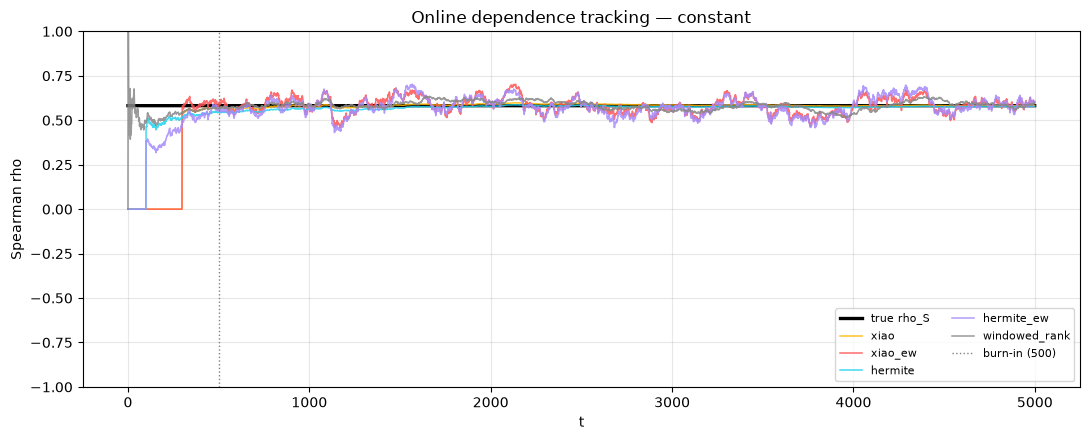

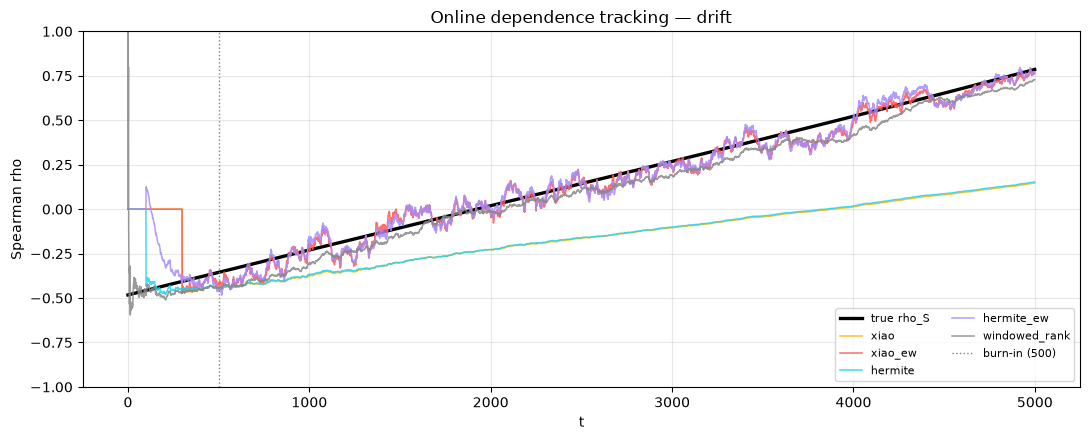

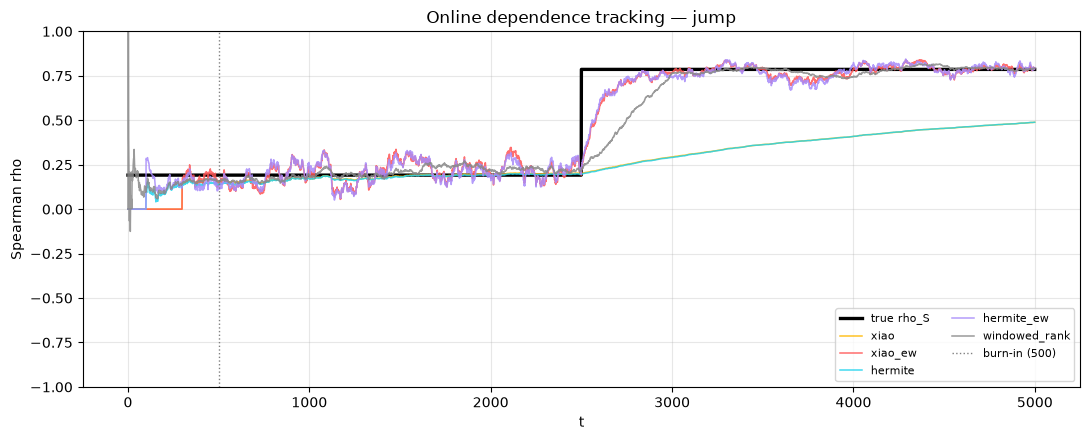

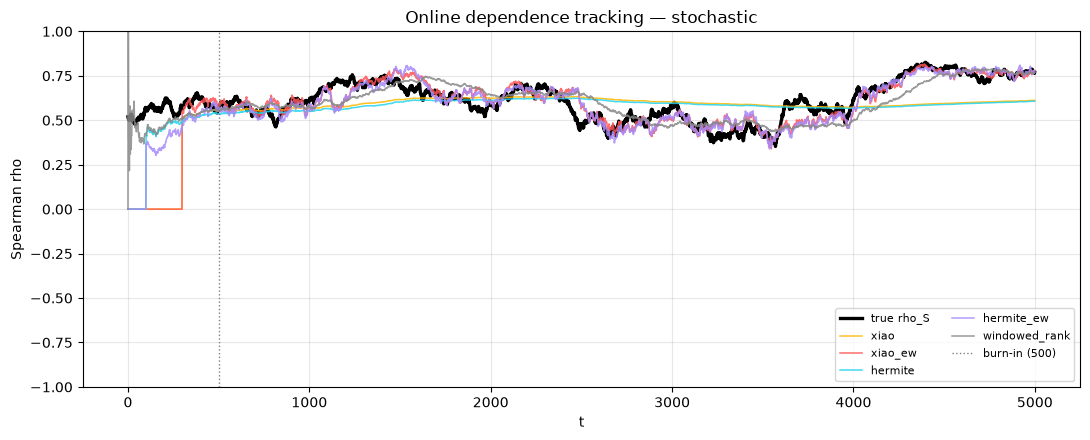

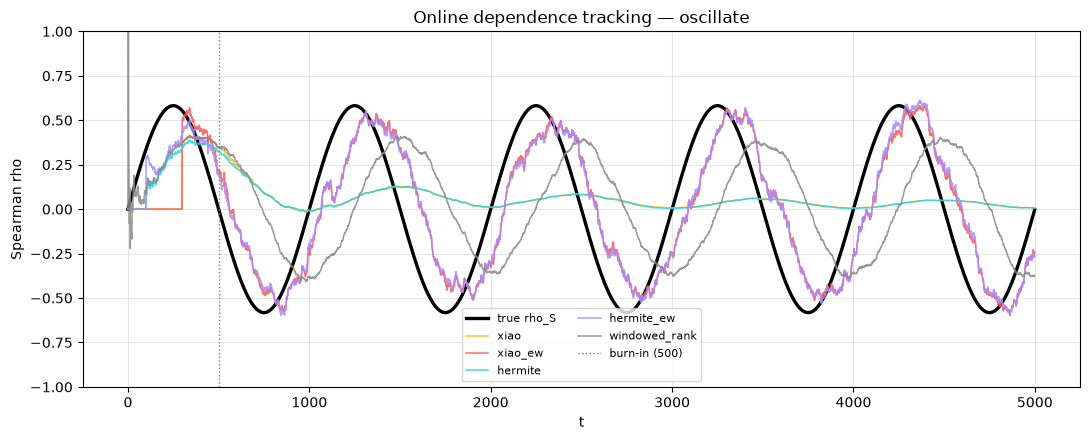

In [11]:
# Tracking plots, one per scenario.
for s in SCENARIOS:
    try:
        plot_scenario(s)
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — run ./experiment {s} first')

In [12]:
# RMSE vs true Spearman (after burn-in): rows = estimators, cols = scenarios.
rows = []
for s in SCENARIOS:
    try:
        rows.append(rmse_table(s))
    except FileNotFoundError:
        print(f'missing experiment_{s}.csv — skipping')
summary = pd.concat(rows, axis=1) if rows else pd.DataFrame()
summary.style.format('{:.4f}').background_gradient(cmap='RdYlGn_r', axis=None) if not summary.empty else summary

,constant,drift,jump,stochastic,oscillate
xiao,0.0070,0.3845,0.3129,0.1131,0.4269
xiao_ew,0.0442,0.0544,0.0779,0.0560,0.2249
hermite,0.0131,0.3806,0.3138,0.1149,0.4256
hermite_ew,0.0498,0.0568,0.0765,0.0579,0.2242
windowed_rank,0.0239,0.0660,0.1142,0.0749,0.4896


## Live probe capture

Plots a capture from `live_probe.py --csv live.csv` (the live server stream). Its columns are
`tick, true_rho_s, <estimators>` — the same shape as the offline CSVs but indexed by `tick`.

Produce one first with, e.g.:
```bash
./server &                                   # or in another terminal
python src/experiments/live_probe.py --csv live.csv
```

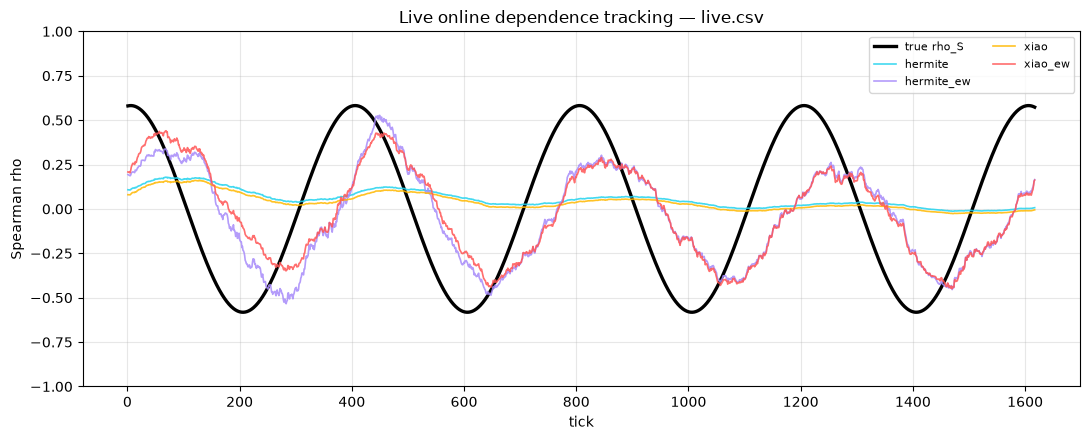

1617 ticks; columns: ['tick', 'true_rho_s', 'hermite', 'hermite_ew', 'xiao', 'xiao_ew']


In [13]:
def plot_live(path='live.csv'):
    # Accept a bare filename (resolved against the repo root) or a full path.
    if not os.path.isabs(path) and not os.path.exists(path):
        path = os.path.join(DATA_DIR, path)
    df = pd.read_csv(path)
    x = 'tick' if 'tick' in df.columns else 't'
    plt.figure(figsize=(11, 4.5))
    plt.plot(df[x], df['true_rho_s'], color='black', lw=2.4, label='true rho_S')
    for col in estimator_cols(df):
        plt.plot(df[x], df[col], lw=1.2, alpha=0.85, color=COLORS.get(col), label=col)
    plt.xlabel(x); plt.ylabel('Spearman rho'); plt.ylim(-1, 1)
    plt.title(f'Live online dependence tracking — {os.path.basename(path)}')
    plt.legend(loc='best', fontsize=8, ncol=2); plt.grid(alpha=0.3)
    plt.tight_layout(); plt.show()
    return df

try:
    live = plot_live('live.csv')
    print(f'{len(live)} ticks; columns: {list(live.columns)}')
except FileNotFoundError:
    print('no live.csv — capture one with: python src/experiments/live_probe.py --csv live.csv')